In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

SEED = 2024
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 110

## Task 1:

### 1-A

In [ ]:
rng = np.random.default_rng(SEED)
n1 = 30
x1 = np.sort(rng.uniform(1, 12, n1))                    # hours studied
true_b0, true_b1 = -6.0, 1.0
y1 = rng.binomial(1, 1 / (1 + np.exp(-(true_b0 + true_b1 * x1))))   # pass / fail
print(n1, "observations; positives:", y1.sum())

30 observations; positives: 16


### 1-B

In [3]:
with pm.Model() as logistic_model:
    beta0 = pm.Normal("beta0", mu=0, sigma=10)
    beta1 = pm.Normal("beta1", mu=0, sigma=10)
    p = pm.math.sigmoid(beta0 + beta1 * x1)
    pm.Bernoulli("obs", p=p, observed=y1)
    trace_log = pm.sample(2000, tune=1000, chains=4, cores=1, random_seed=SEED, progressbar=False)

az.summary(trace_log, var_names=["beta0", "beta1"], hdi_prob=0.95, round_to=4)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [beta0, beta1]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 7 seconds.


There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta0,-8.2327,3.0657,-14.5611,-2.8691,0.1094,0.0820,760.6496,681.9604,1.0072
beta1,1.8084,0.7090,0.5488,3.2140,0.0251,0.0193,766.8297,708.4611,1.0073


### 1-C

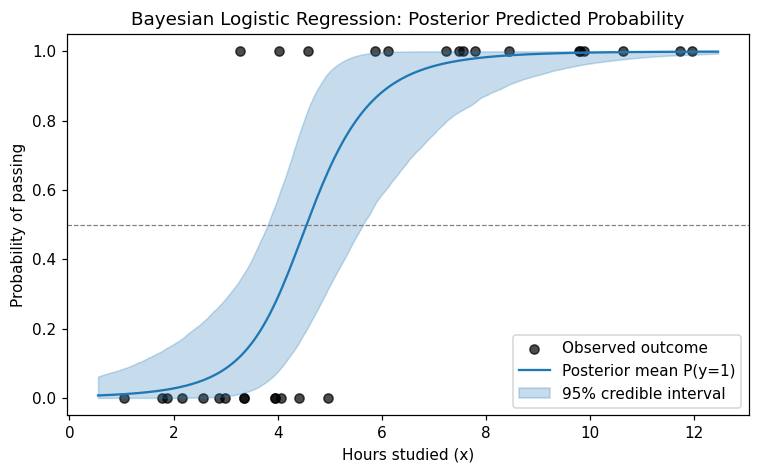

In [4]:
post = trace_log.posterior
b0 = post["beta0"].values.flatten()
b1 = post["beta1"].values.flatten()

xg = np.linspace(x1.min() - 0.5, x1.max() + 0.5, 200)
pg = 1 / (1 + np.exp(-(b0[:, None] + b1[:, None] * xg)))
p_mean = pg.mean(axis=0)
p_lo, p_hi = np.percentile(pg, [2.5, 97.5], axis=0)

plt.figure(figsize=(8, 4.5))
plt.scatter(x1, y1, c="k", alpha=0.7, label="Observed outcome")
plt.plot(xg, p_mean, color="C0", label="Posterior mean P(y=1)")
plt.fill_between(xg, p_lo, p_hi, color="C0", alpha=0.25, label="95% credible interval")
plt.axhline(0.5, ls="--", color="gray", lw=0.8)
plt.xlabel("Hours studied (x)")
plt.ylabel("Probability of passing")
plt.title("Bayesian Logistic Regression: Posterior Predicted Probability")
plt.legend()
plt.show()

### 1-D

In [5]:
p_obs = (1 / (1 + np.exp(-(b0[:, None] + b1[:, None] * x1)))).mean(axis=0)
y1_pred = (p_obs >= 0.5).astype(int)

acc = accuracy_score(y1, y1_pred)
prec = precision_score(y1, y1_pred)
rec = recall_score(y1, y1_pred)
f1 = f1_score(y1, y1_pred)
cm = confusion_matrix(y1, y1_pred)

print(f"Accuracy={acc:.3f}  Precision={prec:.3f}  Recall={rec:.3f}  F1={f1:.3f}")
print("Confusion matrix [[TN FP],[FN TP]]:\n", cm)
print("P(beta1 > 0) =", (b1 > 0).mean())

Accuracy=0.900  Precision=0.933  Recall=0.875  F1=0.903
Confusion matrix [[TN FP],[FN TP]]:
 [[13  1]
 [ 2 14]]
P(beta1 > 0) = 1.0


### 1-E

##### β1: Change in log-odds of y=1 for a 1-unit increase in x.
##### Prediction: Predicted probability of y=1 increases as x increases.
##### Classification: Accuracy, Precision, Recall and F1-score are high; which shows how well the model is.

## Task 2

### 2-A

In [7]:
rng = np.random.default_rng(SEED + 1)
n2 = 30
x2 = np.arange(1, n2 + 1) / 3.0                          # time / exposure index
y2 = rng.poisson(np.exp(0.4 + 0.25 * x2))                # event counts
print(n2, "observations; max count:", y2.max())

30 observations; max count: 19


### 2-B

In [8]:
with pm.Model() as poisson_model:
    beta0 = pm.Normal("beta0", 0, 10)
    beta1 = pm.Normal("beta1", 0, 10)
    mu = pm.math.exp(beta0 + beta1 * x2)
    pm.Poisson("obs", mu=mu, observed=y2)
    trace_poi = pm.sample(2000, tune=1000, chains=4, cores=1, random_seed=SEED, progressbar=False)
    ppc_poi = pm.sample_posterior_predictive(trace_poi, random_seed=SEED, progressbar=False)

az.summary(trace_poi, var_names=["beta0", "beta1"], hdi_prob=0.95, round_to=4)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [beta0, beta1]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 5 seconds.


Sampling: [obs]


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta0,0.6960,0.1873,0.3446,1.0703,0.0044,0.0030,1792.4094,2050.5444,1.0021
beta1,0.2142,0.0259,0.1619,0.2627,0.0006,0.0004,1780.8266,2129.3230,1.0026


### 2-C

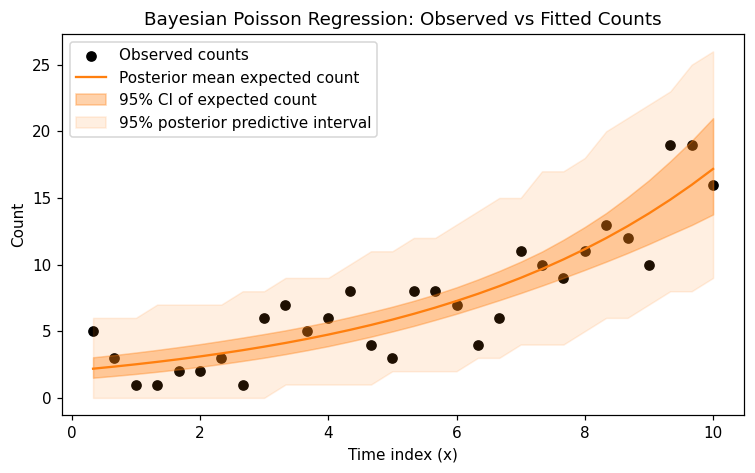

In [9]:
post = trace_poi.posterior
c0 = post["beta0"].values.flatten()
c1 = post["beta1"].values.flatten()

mu_s = np.exp(c0[:, None] + c1[:, None] * x2)            # expected counts
mu_mean = mu_s.mean(axis=0)
mu_lo, mu_hi = np.percentile(mu_s, [2.5, 97.5], axis=0)

ypp = ppc_poi.posterior_predictive["obs"].values.reshape(-1, n2)
pp_lo, pp_hi = np.percentile(ypp, [2.5, 97.5], axis=0)

plt.figure(figsize=(8, 4.5))
plt.scatter(x2, y2, c="k", label="Observed counts")
plt.plot(x2, mu_mean, color="C1", label="Posterior mean expected count")
plt.fill_between(x2, mu_lo, mu_hi, color="C1", alpha=0.35, label="95% CI of expected count")
plt.fill_between(x2, pp_lo, pp_hi, color="C1", alpha=0.12, label="95% posterior predictive interval")
plt.xlabel("Time index (x)")
plt.ylabel("Count")
plt.title("Bayesian Poisson Regression: Observed vs Fitted Counts")
plt.legend()
plt.show()

### 2-D

In [10]:
mae_p = np.mean(np.abs(y2 - mu_mean))
rmse_p = np.sqrt(np.mean((y2 - mu_mean) ** 2))
print(f"MAE={mae_p:.3f}  RMSE={rmse_p:.3f}")
print(f"exp(beta1) mean={np.exp(c1).mean():.3f}, 95% interval={np.percentile(np.exp(c1), [2.5, 97.5]).round(3)}")
print(f"95% predictive interval coverage={np.mean((y2 >= pp_lo) & (y2 <= pp_hi)):.3f}")

MAE=1.768  RMSE=2.088
exp(beta1) mean=1.239, 95% interval=[1.177 1.303]
95% predictive interval coverage=1.000


### 2-E

##### Log link: each one-unit increase in x multiplies the expected count by exp(beta1) ~ 1.24 (95% interval ~[1.18, 1.30]), i.e. about +24% per unit.
##### MAE 1.77 and RMSE 2.09 on counts up to 19; RMSE > MAE because larger counts give larger errors (Poisson variance grows with the mean).
##### The 95% CI of the expected count is narrow (parameter uncertainty), the predictive interval is much wider (count noise) and covers all points.
##### R-hat <= 1.003 and ESS > 1700: no sampling issues.

## Task 3

### 3-A

In [12]:
def run_ssm(T, tau_true, sigma_true, theta0, seed):
    r = np.random.default_rng(seed)
    theta = np.zeros(T)
    theta[0] = theta0
    for t in range(1, T):
        theta[t] = r.normal(theta[t - 1], tau_true)
    y = r.normal(theta, sigma_true)

    with pm.Model():
        tau = pm.HalfNormal("tau", 5)
        sigma = pm.HalfNormal("sigma", 5)
        th = pm.GaussianRandomWalk("theta", sigma=tau, shape=T)
        pm.Normal("obs", mu=th, sigma=sigma, observed=y)
        tr = pm.sample(1000, tune=1500, chains=4, cores=1, target_accept=0.95,
                       random_seed=seed, progressbar=False)

    ts = tr.posterior["theta"].values.reshape(-1, T)
    out = dict(T=T, tau_true=tau_true, sigma_true=sigma_true, theta_true=theta, y=y, trace=tr,
               mean=ts.mean(0), lo=np.percentile(ts, 2.5, 0), hi=np.percentile(ts, 97.5, 0))
    out["rmse"] = np.sqrt(np.mean((out["mean"] - theta) ** 2))
    out["mae"] = np.mean(np.abs(out["mean"] - theta))
    out["width"] = np.mean(out["hi"] - out["lo"])
    out["cover"] = np.mean((theta >= out["lo"]) & (theta <= out["hi"]))
    return out

def plot_ssm(r, title):
    plt.figure(figsize=(10, 4.5))
    plt.plot(r["y"], "o", ms=4, color="gray", label="Observed data")
    plt.plot(r["theta_true"], color="k", label="True hidden state")
    plt.plot(r["mean"], color="C2", label="Posterior mean hidden state")
    plt.fill_between(range(r["T"]), r["lo"], r["hi"], color="C2", alpha=0.25, label="95% credible interval")
    plt.xlabel("Time step")
    plt.ylabel("Value")
    plt.title(title)
    plt.legend()
    plt.show()

# Changes vs the provided code: T 40 -> 60, true_tau 1.5 -> 0.8, true_sigma 3.0 -> 2.0, initial state 50 -> 20, seed 42 -> 7
exp1 = run_ssm(T=60, tau_true=0.8, sigma_true=2.0, theta0=20, seed=7)
print("Experiment 1 fitted: T=60, tau=0.8, sigma=2.0, theta0=20, seed=7")

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [tau, sigma, theta]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 24 seconds.


Experiment 1 fitted: T=60, tau=0.8, sigma=2.0, theta0=20, seed=7


### 3-B

In [13]:
display(az.summary(exp1["trace"], var_names=["tau", "sigma"], hdi_prob=0.95, round_to=4))

# Convergence: R-hat 1.008 (tau) and 1.002 (sigma), both < 1.01; ESS bulk 439 (tau, slowest mixing) and 1319 (sigma): acceptable.
# tau 1.11 [0.63, 1.70] and sigma 1.60 [1.17, 2.06] cover the true values 0.8 and 2.0.

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
tau,1.1089,0.2830,0.6321,1.7027,0.0135,0.0086,439.4075,909.8001,1.0079
sigma,1.6047,0.2263,1.1704,2.0594,0.0063,0.0050,1319.3148,1151.0721,1.0017


### 3-C

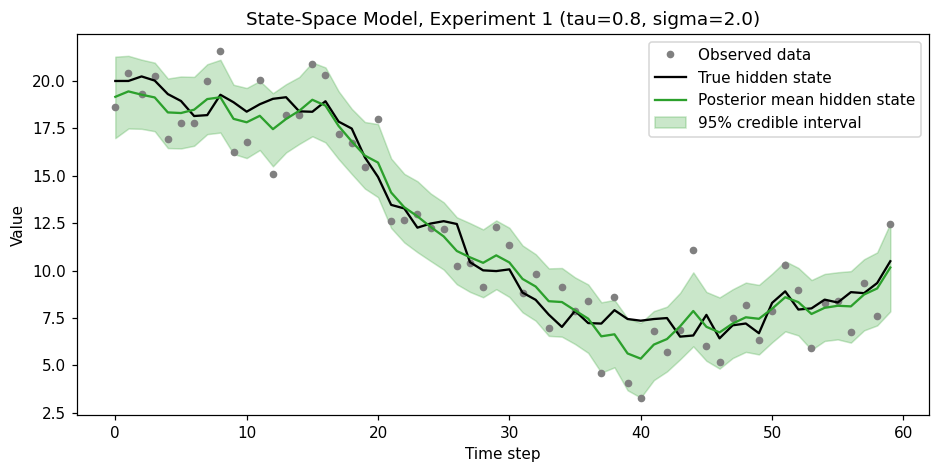

In [14]:
plot_ssm(exp1, "State-Space Model, Experiment 1 (tau=0.8, sigma=2.0)")

### 3-D

In [15]:
print(f"RMSE={exp1['rmse']:.3f}  MAE={exp1['mae']:.3f}  mean 95% width={exp1['width']:.3f}  coverage={exp1['cover']:.3f}")

# RMSE 0.78 / MAE 0.64 are well below the raw observation noise (sigma_true = 2.0): the model smooths the noise.
# 98% of the true states lie inside the 95% credible band.

RMSE=0.781  MAE=0.640  mean 95% width=3.685  coverage=0.983


### 3-E

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [tau, sigma, theta]


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 45 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
tau,1.4406,0.5054,0.5994,2.4522,0.0358,0.0180,189.2210,387.6288,1.0279
sigma,4.1686,0.4660,3.3115,5.1430,0.0097,0.0074,2186.7021,2411.6332,1.0021


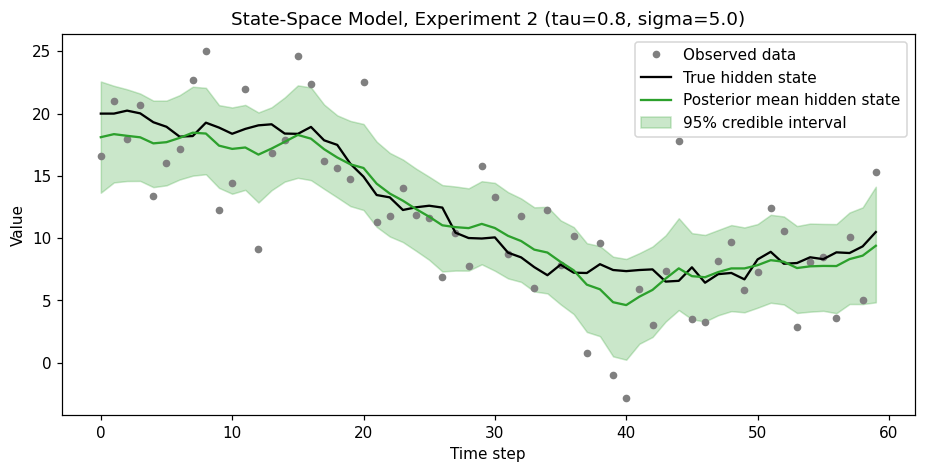

RMSE=1.210  MAE=1.007  mean 95% width=7.072  coverage=1.000


In [ ]:
exp2 = run_ssm(T=60, tau_true=0.8, sigma_true=5.0, theta0=20, seed=7)
display(az.summary(exp2["trace"], var_names=["tau", "sigma"], hdi_prob=0.95, round_to=4))
plot_ssm(exp2, "State-Space Model, Experiment 2 (tau=0.8, sigma=5.0)")
print(f"RMSE={exp2['rmse']:.3f}  MAE={exp2['mae']:.3f}  mean 95% width={exp2['width']:.3f}  coverage={exp2['cover']:.3f}")


## Task 4

### 4-A

In [17]:
ss1 = az.summary(exp1["trace"], var_names=["tau", "sigma"], hdi_prob=0.95, round_to=4)
ss2 = az.summary(exp2["trace"], var_names=["tau", "sigma"], hdi_prob=0.95, round_to=4)
lg = az.summary(trace_log, var_names=["beta0", "beta1"], hdi_prob=0.95, round_to=4)
po = az.summary(trace_poi, var_names=["beta0", "beta1"], hdi_prob=0.95, round_to=4)

rows = []
for model, s, extra in [("Logistic", lg, f"Acc={acc:.2f}, F1={f1:.2f}"),
                        ("Poisson", po, f"MAE={mae_p:.2f}, RMSE={rmse_p:.2f}"),
                        ("State-space Exp1 (sigma=2)", ss1, f"RMSE={exp1['rmse']:.2f}, MAE={exp1['mae']:.2f}"),
                        ("State-space Exp2 (sigma=5)", ss2, f"RMSE={exp2['rmse']:.2f}, MAE={exp2['mae']:.2f}")]:
    for name in s.index:
        rows.append({"Model": model, "Parameter": name, "Mean": s.loc[name, "mean"], "SD": s.loc[name, "sd"],
                     "HDI 2.5%": s.loc[name].iloc[2], "HDI 97.5%": s.loc[name].iloc[3],
                     "R-hat": s.loc[name, "r_hat"], "ESS bulk": s.loc[name, "ess_bulk"], "Performance": extra})
summary_df = pd.DataFrame(rows).round(3)
display(summary_df)

,Model,Parameter,Mean,SD,HDI 2.5%,HDI 97.5%,R-hat,ESS bulk,Performance
0,Logistic,beta0,-8.233,3.066,-14.561,-2.869,1.007,760.650,"Acc=0.90, F1=0.90"
1,Logistic,beta1,1.808,0.709,0.549,3.214,1.007,766.830,"Acc=0.90, F1=0.90"
2,Poisson,beta0,0.696,0.187,0.345,1.070,1.002,1792.409,"MAE=1.77, RMSE=2.09"
3,Poisson,beta1,0.214,0.026,0.162,0.263,1.003,1780.827,"MAE=1.77, RMSE=2.09"
4,State-space Exp1 (sigma=2),tau,1.109,0.283,0.632,1.703,1.008,439.408,"RMSE=0.78, MAE=0.64"
5,State-space Exp1 (sigma=2),sigma,1.605,0.226,1.170,2.059,1.002,1319.315,"RMSE=0.78, MAE=0.64"
6,State-space Exp2 (sigma=5),tau,1.441,0.505,0.599,2.452,1.028,189.221,"RMSE=1.21, MAE=1.01"
7,State-space Exp2 (sigma=5),sigma,4.169,0.466,3.312,5.143,1.002,2186.702,"RMSE=1.21, MAE=1.01"


### 4-B

Logistic (P(y=1))           0.264
Poisson (expected count)    0.145
State-space Exp1            0.202
State-space Exp2            0.254
dtype: float64


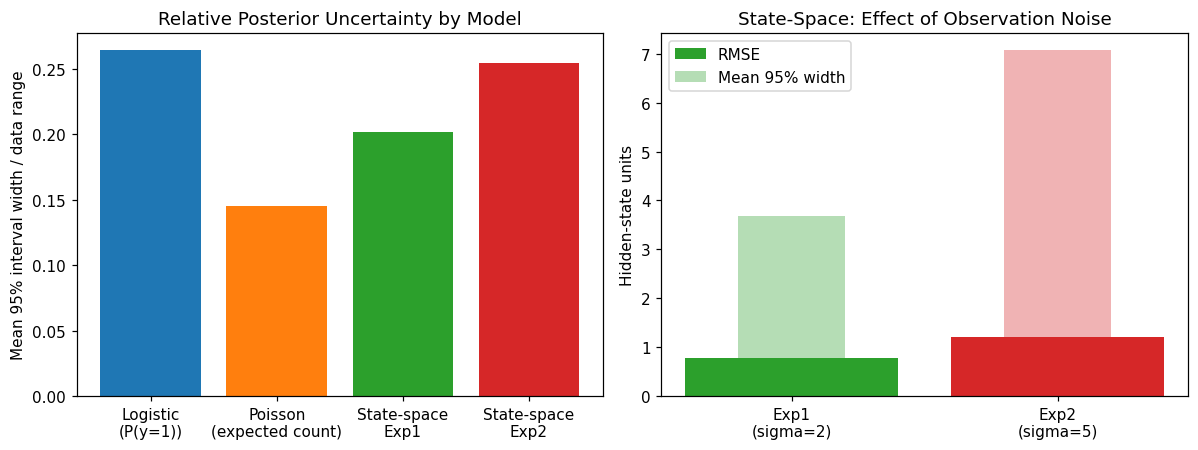

In [18]:
# Relative uncertainty of the latent quantity in each model (mean 95% interval width / range of the observed data)
p_s = 1 / (1 + np.exp(-(b0[:, None] + b1[:, None] * x1)))
widths = {
    "Logistic\n(P(y=1))": np.mean(np.percentile(p_s, 97.5, 0) - np.percentile(p_s, 2.5, 0)),
    "Poisson\n(expected count)": np.mean(mu_hi - mu_lo) / (y2.max() - y2.min()),
    "State-space\nExp1": exp1["width"] / (exp1["y"].max() - exp1["y"].min()),
    "State-space\nExp2": exp2["width"] / (exp2["y"].max() - exp2["y"].min()),
}
print(pd.Series(widths).round(3).rename(lambda k: k.replace("\n", " ")))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].bar(widths.keys(), widths.values(), color=["C0", "C1", "C2", "C3"])
ax[0].set_ylabel("Mean 95% interval width / data range")
ax[0].set_title("Relative Posterior Uncertainty by Model")
ax[1].bar(["Exp1\n(sigma=2)", "Exp2\n(sigma=5)"], [exp1["rmse"], exp2["rmse"]], color=["C2", "C3"], label="RMSE")
ax[1].bar(["Exp1\n(sigma=2)", "Exp2\n(sigma=5)"], [exp1["width"], exp2["width"]], color=["C2", "C3"], alpha=0.35, width=0.4, label="Mean 95% width")
ax[1].set_ylabel("Hidden-state units")
ax[1].set_title("State-Space: Effect of Observation Noise")
ax[1].legend()
plt.tight_layout()
plt.show()

### 4-C

##### Uncertainty types: Logistic = parameter uncertainty in beta0/beta1 carried into P(y=1), while each outcome stays a Bernoulli draw (irreducible).
##### Poisson = narrow parameter uncertainty plus Poisson count noise (the predictive interval is far wider than the CI of the mean).
##### State-space = uncertainty over a whole latent trajectory plus the noise scales tau and sigma; it grows when observation noise grows.
##### Observations: the logistic model is least certain (30 binary points, wide beta posteriors); the Poisson parameters are the most precise;
##### in the state-space model, raising sigma from 2 to 5 doubled the band width and raised RMSE by about 55%.

### 4-D